In [1]:
from data_processing import build_patient_dataframe

df_all = build_patient_dataframe()
df_filtered = df_all[df_all["Patient eGFR"] <= 65].copy()

print(f"Total patients: {len(df_all)}")
print(f"Patients with eGFR <= 65: {len(df_filtered)}")

stats_table = df_filtered[["Patient Age", "Patient Height", "Patient Weight"]].describe()
stats_table

Total patients: 100
Patients with eGFR <= 65: 41


,Patient Age,Patient Height,Patient Weight
count,41.000000,41.000000,41.000000
mean,41.439024,72.634146,221.902439
std,14.615144,7.415376,38.822548
min,18.000000,61.000000,144.000000
25%,29.000000,65.000000,194.000000
50%,40.000000,73.000000,224.000000
75%,56.000000,79.000000,247.000000
max,64.000000,84.000000,298.000000


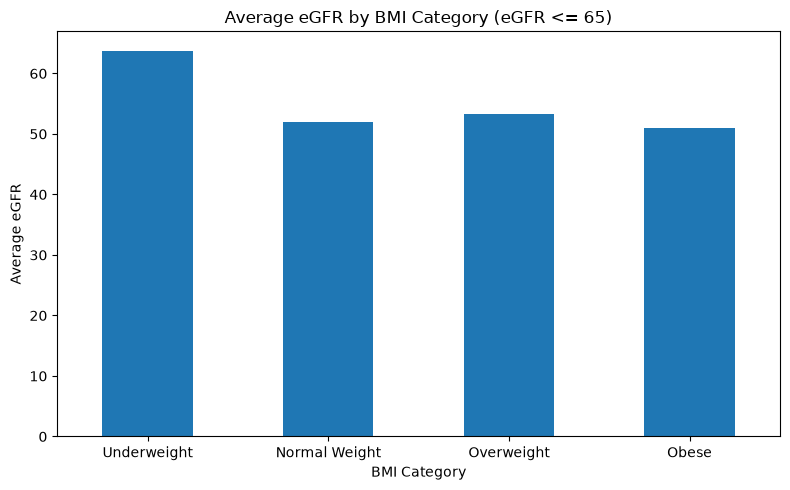

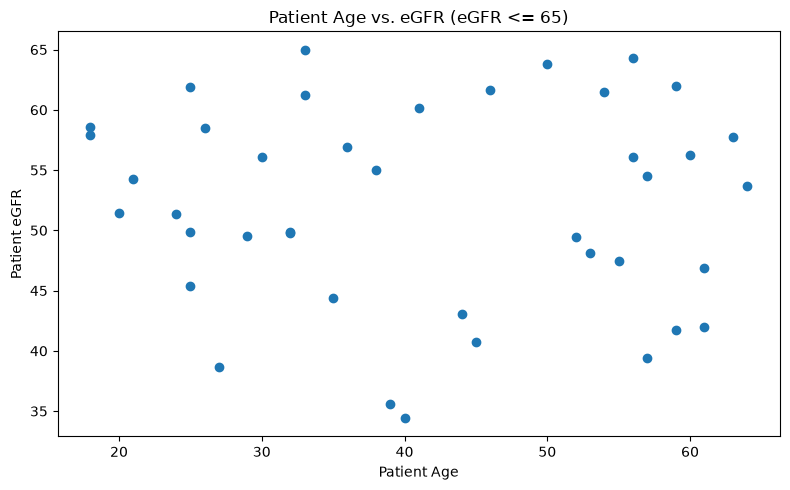

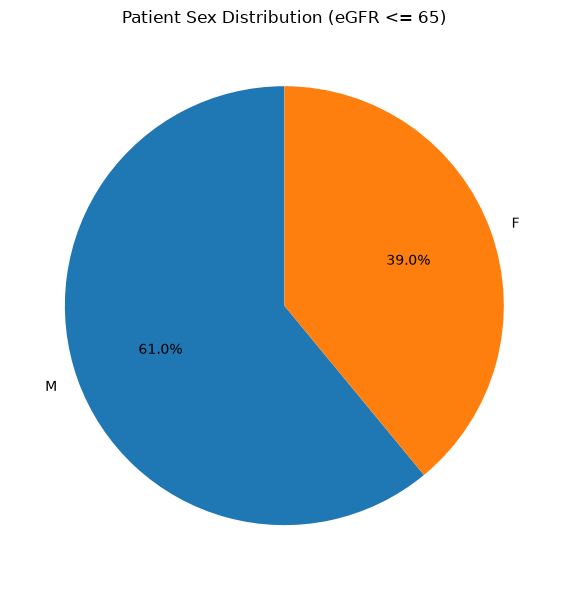

In [2]:
import matplotlib.pyplot as plt
import pandas as pd


def categorize_bmi(bmi: float) -> str:
    """Assign BMI category based on assignment thresholds."""
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25.0:
        return "Normal Weight"
    elif bmi < 30.0:
        return "Overweight"
    else:
        return "Obese"


bmi_order = ["Underweight", "Normal Weight", "Overweight", "Obese"]
df_filtered["BMI Category"] = pd.Categorical(
    df_filtered["Patient BMI"].apply(categorize_bmi),
    categories=bmi_order,
    ordered=True,
)

# 1. Bar chart: Average eGFR by BMI category
avg_egfr_by_bmi = (
    df_filtered.groupby("BMI Category", observed=False)["Patient eGFR"].mean()
)

plt.figure(figsize=(8, 5))
avg_egfr_by_bmi.plot(kind="bar")
plt.title("Average eGFR by BMI Category (eGFR <= 65)")
plt.xlabel("BMI Category")
plt.ylabel("Average eGFR")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Scatter plot: Patient Age (X) vs. Patient eGFR (Y)
plt.figure(figsize=(8, 5))
plt.scatter(df_filtered["Patient Age"], df_filtered["Patient eGFR"])
plt.title("Patient Age vs. eGFR (eGFR <= 65)")
plt.xlabel("Patient Age")
plt.ylabel("Patient eGFR")
plt.tight_layout()
plt.show()

# 3. Pie chart: Patient Sex
sex_counts = df_filtered["Patient Sex"].value_counts()

plt.figure(figsize=(6, 6))
sex_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Patient Sex Distribution (eGFR <= 65)")
plt.ylabel("")
plt.tight_layout()
plt.show()